# **Application RAG Multimodale et Agentique**
### *Extraction, Indexation Vectorielle Latente (CLIP & ChromaDB) et Cycle ReAct avec LangGraph*

**Réalisé par :** **Walid IDIR**  
**Architecture :** RAG Multimodal Hybride (Textes & Images) + Agent Autonome ReAct (LangGraph / LangChain)  
**Document source :** *"Attention Is All You Need"* (Vaswani et al., 2017)

---

### **Objectifs du Projet :**
1. **Extraction Multimodale :** Extraire automatiquement le texte intégral (découpé par fragments) et les figures visuelles intégrées dans le document PDF.
2. **Espace Latent Conjoint (CLIP) :** Projeter conjointement les fragments textuels et les images dans le même espace vectoriel à 512 dimensions via le modèle multimodal **CLIP ViT-B-32** avec normalisation $L_2$.
3. **Indexation Vectorielle (ChromaDB) :** Stocker de façon persistante les vecteurs, les fragments et les métadonnées avec gestion d'invalidation par empreinte cryptographique **SHA-256**.
4. **Retrieval Multimodal :** Développer un moteur de recherche par similarité cosinus acceptant indifféremment des requêtes sous forme de texte ou d'image.
5. **Encapsulation Agentique (Tool) :** Transformer le moteur de recherche en un outil agentique structuré (`retriever_tool`) guidé par des métadonnées descriptives.
6. **Agent ReAct & LangGraph :** Construire l'agent articulé autour du Cerveau (**MIND** - LLM) et du Corps (**BODY** - Retriever Tool) selon le pattern de raisonnement **ReAct** (*Reasoning $\to$ Action $\to$ Observation*) orchestré par un graphe d'états **LangGraph**.
7. **Validation & Analyse Dynamique :** Soumettre des requêtes complexes (textuelles, visuelles et hybrides) et analyser en profondeur la dynamique décisionnelle de l'agent.


### **Architecture Globale du Système (MIND & BODY ReAct)**

```
┌─────────────────────────────────────────────────────────────────────────────┐
│                              AGENT IA (LANGGRAPH)                           │
│                                                                             │
│               ┌──────────────────────────────────────────────┐              │
│               │             CERVEAU (MIND - LLM)             │              │
│               │  - Raisonnement (Thought / Reasoning)         │              │
│               │  - Décomposition de requête complexe          │              │
│               │  - Décision d'appel d'outil (Action)         │              │
│               │  - Synthèse contextuelle multimodale         │              │
│               └──────────────────────┬───────────────────────┘              │
│                                      │                                      │
│                         Action       │    ▲ Observation                     │
│                       (Tool Call)    │    │ (Sources & Images)              │
│                                      ▼    │                                 │
│               ┌──────────────────────────────────────────────┐              │
│               │         CORPS (BODY - RETRIEVER TOOL)        │              │
│               │  - Filtrage (texte, image, tous)             │              │
│               │  - Normalisation & similarité cosinus        │              │
│               └──────────────────────┬───────────────────────┘              │
└──────────────────────────────────────┼──────────────────────────────────────┘
                                       │
                      Interrogation    ▼
┌─────────────────────────────────────────────────────────────────────────────┐
│                        BASE VECTORIELLE (CHROMADB)                          │
│                                                                             │
│        Vecteurs Textes (512d)      │        Vecteurs Images (512d)          │
│   ┌─────────────────────────────┐  │   ┌─────────────────────────────┐      │
│   │ Fragments "Attention is..." │  │   │ Fig 1: Architecture Diagram │      │
│   │ Métadonnées : Page, SHA256  │  │   │ Fig 2: Multi-Head Attention │      │
│   └─────────────────────────────┘  │   └─────────────────────────────┘      │
│                                    │                                        │
│           Modèle d'Embedding Partagé : OpenCLIP ViT-B-32                    │
└─────────────────────────────────────────────────────────────────────────────┘
```


## Dépendances requises

Pour exécuter l'ensemble de ce pipeline, assurez-vous que les packages suivants sont installés :
- `pymupdf` (extraction PDF texte et images)
- `open_clip_torch`, `torch`, `torchvision`, `pillow` (modèle CLIP et traitement d'images)
- `chromadb` (base de données vectorielle HNSW)
- `langchain`, `langchain-core`, `langchain-openai`, `langgraph` (framework agentique)


In [1]:
import os
import re
import json
import base64
import hashlib
from io import BytesIO
from pathlib import Path
from typing import Annotated, Sequence, TypedDict, Literal, Optional, Dict, Any, List

import torch
import open_clip
from open_clip.tokenizer import SimpleTokenizer
from PIL import Image
import pymupdf
import chromadb
from IPython.display import display, Markdown

# Détection du matériel d'accélération
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Appareil de calcul utilisé : {DEVICE}")

# Configuration des répertoires et robustesse multi-environnements
BASE_DIR = Path.cwd()
if (Path(r"C:/Users/user/Desktop/TP IA RAG") / "pdfs").is_dir():
    BASE_DIR = Path(r"C:/Users/user/Desktop/TP IA RAG")

PDF_DIR = BASE_DIR / "pdfs"
OUTPUT_DIR = BASE_DIR / "resultats_pdf"
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"
CHROMA_DIR = BASE_DIR / "chroma_pdf"

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
CHROMA_DIR.mkdir(parents=True, exist_ok=True)

# Localisation du document source PDF
candidats_pdf = [
    PDF_DIR / "attention is all you need.pdf",
    BASE_DIR / "attention is all you need.pdf",
    BASE_DIR / "attention is all you need (2).pdf",
    Path(r"C:/Users/user/Desktop/TP IA RAG/pdfs/attention is all you need.pdf"),
    Path(r"C:/Users/user/Desktop/TP IA RAG/attention is all you need (2).pdf"),
]
PDF_PATH = next((p for p in candidats_pdf if p.is_file()), None)

if PDF_PATH is None:
    raise FileNotFoundError("Document PDF source 'Attention is all you need' introuvable.")

print(f"Répertoire de travail : {BASE_DIR.resolve()}")
print(f"Fichier PDF identifié : {PDF_PATH.resolve()}")


C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Appareil de calcul utilisé : cpu
Répertoire de travail : C:\Users\user\Desktop\TP IA RAG
Fichier PDF identifié : C:\Users\user\Desktop\TP IA RAG\pdfs\attention is all you need.pdf


# **Étape 1 : Extraction du contenu multimodal (Textes & Images)**

Dans cette première étape, nous analysons la structure interne du document PDF à l'aide de **PyMuPDF** (`fitz`).  
Le document est décomposé selon deux canaux complémentaires :
1. **Le texte intégral :** extrait page par page en conservant l'ordre de lecture naturel (`sort=True`). Chaque page est sauvegardée dans un fichier texte dédié (`page_XXX.txt`), et l'intégralité du document est consolidée dans `texte_complet.txt`.
2. **Les images intégrées :** identification des flux visuels (`page.get_images()`), déduplication par référence `xref` interne et sauvegarde sous forme de fichiers PNG/JPEG (`page_XXX_image_YYY.png`).


In [2]:
# Extraction intégrale des textes et des figures visuelles
textes_document = []
nombre_images_extraites = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)
    print(f"Traitement de '{PDF_PATH.name}' ({nombre_pages} pages)...")

    for numero_page, page in enumerate(document, start=1):
        # 1. Extraction textuelle
        texte = page.get_text("text", sort=True)
        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")
        textes_document.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # 2. Extraction des images intégrées
        images_vues = set()
        for image_info in page.get_images(full=True):
            xref = image_info[0]
            if xref in images_vues:
                continue
            images_vues.add(xref)

            try:
                flux_image = document.extract_image(xref)
                if not flux_image:
                    continue

                extension = flux_image["ext"]
                fichier_image = IMAGE_DIR / f"page_{numero_page:03d}_image_{xref}.{extension}"
                fichier_image.write_bytes(flux_image["image"])
                nombre_images_extraites += 1

                # Conserver une copie de la figure 1 comme image de référence
                if numero_page == 3 and not (BASE_DIR / "architecture_transformer.png").exists():
                    (BASE_DIR / "architecture_transformer.png").write_bytes(flux_image["image"])

            except Exception as erreur:
                print(f"Erreur d'extraction sur la page {numero_page}, xref {xref} : {erreur}")

# Consolider le texte intégral
(OUTPUT_DIR / "texte_complet.txt").write_text("\n\n".join(textes_document), encoding="utf-8")

print(f"Extraction terminée avec succès :")
print(f" - Pages traitées : {nombre_pages}")
print(f" - Images extraites : {nombre_images_extraites}")
if pages_sans_texte:
    print(f" - Pages sans texte détecté : {pages_sans_texte}")


Traitement de 'attention is all you need.pdf' (14 pages)...


Extraction terminée avec succès :
 - Pages traitées : 14
 - Images extraites : 3


### **Vérification et aperçu des données extraites**
Visualisons un échantillon du texte extrait ainsi que les figures récupérées dans le document (*notamment l'architecture du Transformer en Page 3 et les mécanismes d'attention en Page 4*).


=== APERÇU DU TEXTE EXTRAIT (500 premiers caractères) ===
===== PAGE 1 =====

              Attention Is All You Need
                       Google Brain     noam@google.com        Google
                    avaswani@google.co        Niki Parmar∗        Research
                  m           Google Research     usz@google.co
                       Noam        nikip@google.co       m
                            Shazeer∗        m
     Ashish Vaswani∗       Google Brain     Jakob Uszkoreit∗
                                University of Toronto     Google 
...

=== APERÇU DES FIGURES DU DOCUMENT ===
Fichier : page_003_image_11.png


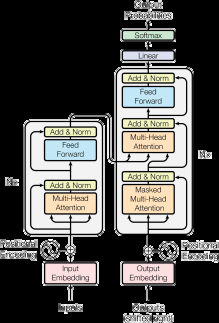

Fichier : page_004_image_16.png


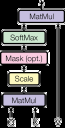

Fichier : page_004_image_18.png


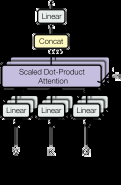

In [3]:
# Aperçu du texte extrait
texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(encoding="utf-8")
print("=== APERÇU DU TEXTE EXTRAIT (500 premiers caractères) ===")
print(texte_complet[:500] + "\n...\n")

# Aperçu des images extraites
print("=== APERÇU DES FIGURES DU DOCUMENT ===")
for fichier_img in sorted(IMAGE_DIR.iterdir()):
    if fichier_img.suffix.lower() in [".png", ".jpg", ".jpeg"]:
        print(f"Fichier : {fichier_img.name}")
        with Image.open(fichier_img) as img:
            apercu = img.copy()
            apercu.thumbnail((450, 450))
            display(apercu)


# **Étape 2 : Vectorisation dans un espace latent commun (Embeddings)**

### **Principe théorique de CLIP (Contrastive Language-Image Pre-Training)**
Contrairement aux modèles de texte purs (BERT, text-embedding-3) qui ne peuvent pas traiter d'images, ou aux modèles de vision (ResNet, ViT) incapables de traiter du texte arbitraire, **CLIP** projette les deux modalités dans un **espace géométrique commun à 512 dimensions**.

Un texte décrivant une architecture et l'image du diagramme de cette architecture auront des vecteurs d'embeddings orientés dans la même direction dans la sphère unité :
$$\cos(\theta) = \frac{\mathbf{v}_{texte} \cdot \mathbf{v}_{image}}{\|\mathbf{v}_{texte}\|_2 \|\mathbf{v}_{image}\|_2}$$

### **Normalisation $L_2$ des vecteurs**
Pour garantir que la similarité cosinus soit équivalente au simple produit scalaire (*dot product*), tous les vecteurs sont rigoureusement normalisés :
$$\mathbf{v}_{norm} = \frac{\mathbf{v}}{\max(\|\mathbf{v}\|_2, \epsilon)}$$


In [4]:
# Chargement du modèle multimodal CLIP ViT-B-32 via OpenCLIP
MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

print(f"Chargement du modèle {MODEL_NAME} ({PRETRAINED}) sur {DEVICE}...")
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)
clip_model = clip_model.to(DEVICE).eval()

# Tokenizer BPE pour CLIP
clip_tokenizer = open_clip.get_tokenizer(MODEL_NAME)
bpe_tokenizer = SimpleTokenizer()
print("Modèle CLIP et préprocesseur chargés avec succès.")

# Fonctions d'encodage avec normalisation L2 stricte
@torch.inference_mode()
def encoder_textes(textes: List[str]) -> List[List[float]]:
    """Encode une liste de fragments textuels en vecteurs normalisés de dimension 512."""
    tokens = clip_tokenizer(textes).to(DEVICE)
    vecteurs = clip_model.encode_text(tokens).float()
    vecteurs = vecteurs / vecteurs.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return vecteurs.cpu().tolist()

@torch.inference_mode()
def encoder_image(chemin_image: Path | str) -> List[float]:
    """Encode une image en un vecteur normalisé de dimension 512."""
    chemin = Path(chemin_image)
    if not chemin.is_file():
        raise FileNotFoundError(f"Fichier image introuvable : {chemin}")
    with Image.open(chemin) as img:
        tenseur = clip_preprocess(img.convert("RGB")).unsqueeze(0).to(DEVICE)
    vecteur = clip_model.encode_image(tenseur).float()
    vecteur = vecteur / vecteur.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return vecteur.cpu().tolist()[0]

# Validation de l'encodage conjoint
vec_txt_test = encoder_textes(["The Transformer model architecture"])[0]
vec_img_test = encoder_image(list(IMAGE_DIR.glob("*.png"))[0])
print(f"Dimension vecteur texte : {len(vec_txt_test)}")
print(f"Dimension vecteur image : {len(vec_img_test)}")
print(f"Norme L2 vecteur texte : {sum(x**2 for x in vec_txt_test):.4f}")
print(f"Norme L2 vecteur image : {sum(x**2 for x in vec_img_test):.4f}")


Chargement du modèle ViT-B-32 (laion2b_s34b_b79k) sur cpu...


Modèle CLIP et préprocesseur chargés avec succès.


Dimension vecteur texte : 512
Dimension vecteur image : 512
Norme L2 vecteur texte : 1.0000
Norme L2 vecteur image : 1.0000


### **Découpage du texte en fragments (Chunking)**
Le modèle CLIP est conçu avec une fenêtre contextuelle limitée à 77 tokens.  
Pour obtenir des représentations denses et pertinentes, nous implémentons un découpage par taille de fenêtre adaptée (60 tokens avec chevauchement de 10 tokens), ainsi qu'une variante sémantique basée sur les sauts de lignes et paragraphes.


In [5]:
def decouper_texte(texte: str, taille: int = 60, chevauchement: int = 10):
    """Découper le texte en fragments courts de tokens BPE adaptés à CLIP."""
    if not (0 <= chevauchement < taille):
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    tokens = bpe_tokenizer.encode(texte)
    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe_tokenizer.decode(tokens[debut:debut + taille]).strip()
        if fragment:
            yield fragment
        if debut + taille >= len(tokens):
            break

# Test sur le texte de la première page
texte_p1 = (TEXT_DIR / "page_001.txt").read_text(encoding="utf-8")
fragments_test = list(decouper_texte(texte_p1))
print(f"Page 1 découpée en {len(fragments_test)} fragments.")
print("Exemple de fragment :", fragments_test[0][:120], "...")


Page 1 découpée en 13 fragments.
Exemple de fragment : attention is all you need google brain noam @ google . com google avaswani @ google . co niki parmar ∗ research m google ...


# **Étape 3 : Indexation et stockage dans une base de données vectorielle**

### **Initialisation de ChromaDB et Gestion des Réindexations (SHA-256)**
Pour gérer les versions et éviter les duplications lors des réindexations :
1. Nous calculons le hachage **SHA-256** du fichier PDF original.
2. Si le document a déjà été indexé, ses anciens fragments sont purgés grâce au filtre de métadonnées `where={"document_id": document_id}`.
3. Les fragments textuels et les images sont indexés dans la **même collection** avec la métrique de distance cosinus (`hnsw:space: cosine`).


In [6]:
# Initialisation du client persistant ChromaDB
client_chroma = chromadb.PersistentClient(path=str(CHROMA_DIR))

# Création ou récupération de la collection avec métrique cosinus
collection = client_chroma.get_or_create_collection(
    name="pdf_clip_vit_b32",
    embedding_function=None,  # Embeddings calculés explicitement par notre modèle CLIP
    metadata={"hnsw:space": "cosine"}
)

# 1. Calcul de l'identifiant unique du document via hachage SHA-256
document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]
print(f"Identifiant SHA-256 du document : {document_id}")

# 2. Nettoyage préventif des anciennes versions pour garantir l'idempotence
elements_anciens = collection.get(where={"document_id": document_id})
if elements_anciens["ids"]:
    print(f"Suppression de {len(elements_anciens['ids'])} anciens fragments associés à cet ID...")
    collection.delete(where={"document_id": document_id})

def extraire_numero_page(chemin: Path | str) -> int:
    correspondance = re.search(r"page_(\d+)", Path(chemin).stem)
    return int(correspondance.group(1)) if correspondance else -1

# 3. Indexation des fragments textuels
ids_textes = []
documents_textes = []
metadonnées_textes = []

for fichier_page in sorted(TEXT_DIR.glob("page_*.txt")):
    contenu_page = fichier_page.read_text(encoding="utf-8")
    num_page = extraire_numero_page(fichier_page)

    for index_fragment, fragment in enumerate(decouper_texte(contenu_page)):
        ids_textes.append(f"{document_id}:texte:{num_page:03d}:{index_fragment:03d}")
        documents_textes.append(fragment)
        metadonnées_textes.append({
            "type": "texte",
            "document_id": document_id,
            "pdf": PDF_PATH.name,
            "page": num_page,
            "fragment": index_fragment,
            "source": str(fichier_page.resolve())
        })

# Indexation par lots (batching) pour optimiser les performances
TAILLE_LOT = 64
for i in range(0, len(documents_textes), TAILLE_LOT):
    lot_docs = documents_textes[i:i + TAILLE_LOT]
    lot_ids = ids_textes[i:i + TAILLE_LOT]
    lot_meta = metadonnées_textes[i:i + TAILLE_LOT]
    lot_embeddings = encoder_textes(lot_docs)

    collection.upsert(
        ids=lot_ids,
        documents=lot_docs,
        metadatas=lot_meta,
        embeddings=lot_embeddings
    )

print(f"Fragments de texte indexés : {len(documents_textes)}")

# 4. Indexation des images dans la même collection
extensions_valides = {".png", ".jpg", ".jpeg", ".webp"}
nombre_images_indexees = 0

for fichier_image in sorted(IMAGE_DIR.iterdir()):
    if fichier_image.suffix.lower() not in extensions_valides:
        continue

    try:
        vecteur_img = encoder_image(fichier_image)
        num_page = extraire_numero_page(fichier_image)

        collection.upsert(
            ids=[f"{document_id}:image:{fichier_image.name}"],
            embeddings=[vecteur_img],
            documents=[f"Image extraite du PDF : {fichier_image.name} (Page {num_page})"],
            metadatas=[{
                "type": "image",
                "document_id": document_id,
                "pdf": PDF_PATH.name,
                "page": num_page,
                "source": str(fichier_image.resolve())
            }]
        )
        nombre_images_indexees += 1
    except Exception as e:
        print(f"Erreur d'indexation de l'image {fichier_image.name} : {e}")

print(f"Images indexées : {nombre_images_indexees}")
print(f"Total d'éléments stockés dans ChromaDB : {collection.count()}")


Identifiant SHA-256 du document : 6dd338cd7ef1fa6db67068e0


Suppression de 175 anciens fragments associés à cet ID...


Fragments de texte indexés : 172


Images indexées : 3
Total d'éléments stockés dans ChromaDB : 175


# **Étape 4 : Implémentation de la recherche multimodale (Retrieval)**

La recherche par similarité cosinus s'appuie sur le calcul d'angle entre la requête (projetée par CLIP) et les vecteurs de la base ChromaDB :
$$\text{Similarité Cosinus} = 1 - \text{Distance Cosinus}$$

Notre fonction `rechercher` est bidirectionnelle et universelle :
- **Entrée :** soit une chaîne de texte, soit un chemin de fichier image.
- **Filtre `type_resultat` :** `None` (recherche tous azimuts), `"texte"` (filtrage strict sur les passages écrits), `"image"` (recherche visuelle des figures).
- **Affichage :** la fonction `afficher_resultats` met en forme les extraits de texte et affiche directement les aperçus graphiques des figures correspondantes.


In [7]:
def rechercher(texte: Optional[str] = None, image: Optional[str | Path] = None, type_resultat: Optional[str] = None, k: int = 5):
    """
    Effectue une recherche multimodale par similarité cosinus dans ChromaDB.
    Fournir obligatoirement soit un texte, soit un chemin d'image.
    """
    if (texte is None) == (image is None):
        raise ValueError("Veuillez fournir soit un texte, soit une image (exactement un des deux).")

    if type_resultat not in (None, "texte", "image", "tous"):
        raise ValueError("type_resultat doit être 'texte', 'image', 'tous' ou None.")

    total = collection.count()
    if total == 0:
        raise ValueError("La collection ChromaDB est vide.")

    # Calcul de l'embedding de la requête
    if texte is not None:
        vecteur_requete = encoder_textes([texte])[0]
    else:
        vecteur_requete = encoder_image(image)

    # Filtrage éventuel sur les métadonnées
    options = {}
    if type_resultat and type_resultat != "tous":
        options["where"] = {"type": type_resultat}

    # Interrogation vectorielle
    return collection.query(
        query_embeddings=[vecteur_requete],
        n_results=min(k, total),
        include=["documents", "metadatas", "distances"],
        **options
    )

def afficher_resultats(resultats: Dict[str, Any]):
    """Affiche de façon lisible et visuelle les résultats retournés par ChromaDB."""
    if not resultats["documents"] or not resultats["documents"][0]:
        print("Aucun résultat trouvé.")
        return

    for rang, (doc, meta, dist) in enumerate(zip(
        resultats["documents"][0],
        resultats["metadatas"][0],
        resultats["distances"][0]
    ), start=1):
        similarite = 1.0 - dist
        print(f"\n--- [Résultat {rang}] Type : {meta['type'].upper()} | Page : {meta['page']} | Similarité : {similarite:.3f} ---")

        if meta["type"] == "image":
            chemin_img = Path(meta["source"])
            print(f"Figure : {chemin_img.name}")
            if chemin_img.is_file():
                with Image.open(chemin_img) as im:
                    apercu = im.copy()
                    apercu.thumbnail((500, 400))
                    display(apercu)
            else:
                print(f"Image introuvable : {chemin_img}")
        else:
            print(f"Extrait : {doc}")


### **Validation de la recherche multimodale sur trois scénarios distincts**


In [8]:
# Scénario A : Requête textuelle conceptuelle -> Recherche mixte (textes et images)
print("=== SCÉNARIO A : Requête texte -> Résultats mixtes ===")
res_a = rechercher(texte="Scaled Dot-Product Attention mechanism", k=4)
afficher_resultats(res_a)


=== SCÉNARIO A : Requête texte -> Résultats mixtes ===



--- [Résultat 1] Type : TEXTE | Page : 5 | Similarité : 0.686 ---


Extrait : attention ( q , k , v ) = softmax ( qkt √ dk ) v ( 1 ) the two most commonly used attention functions are additive attention [ 2 ], and dot - product ( multi plicative ) attention . dot - product attention is identical to our algorithm , except for the scaling

--- [Résultat 2] Type : TEXTE | Page : 4 | Similarité : 0.637 ---
Extrait : consists of queries and keys of dimension dk , and values of dimension dv . we compute the dot products of the 3 scaled dot - product attention multi - head attention figure 2 : ( left ) scaled dot - product attention . ( right ) multi - head attention consists of several attention layers running in parallel

--- [Résultat 3] Type : TEXTE | Page : 6 | Similarité : 0.635 ---
Extrait : the decoder allow each position in the decoder to attend to all positions in the decoder up to and including that position . we need to prevent leftward information flow in the decoder to preserve the auto - regressive property . we implement this inside of scaled

=== SCÉNARIO B : Requête texte -> Figure du modèle Transformer ===



--- [Résultat 1] Type : IMAGE | Page : 3 | Similarité : 0.264 ---
Figure : page_003_image_11.png


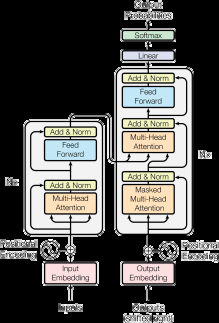


--- [Résultat 2] Type : IMAGE | Page : 4 | Similarité : 0.247 ---
Figure : page_004_image_16.png


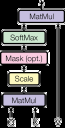

In [9]:
# Scénario B : Requête textuelle ciblant une figure -> Filtrage type="image"
print("=== SCÉNARIO B : Requête texte -> Figure du modèle Transformer ===")
res_b = rechercher(texte="The Transformer model architecture diagram", type_resultat="image", k=2)
afficher_resultats(res_b)


In [10]:
# Scénario C : Requête à partir d'une image en entrée -> Recherche de textes explicatifs
image_entree = (BASE_DIR / "architecture_transformer.png")
if image_entree.is_file():
    print(f"=== SCÉNARIO C : Requête Image ({image_entree.name}) -> Fragments de texte explicatifs ===")
    res_c = rechercher(image=image_entree, type_resultat="texte", k=3)
    afficher_resultats(res_c)
else:
    print("Image 'architecture_transformer.png' absente pour le test C.")


=== SCÉNARIO C : Requête Image (architecture_transformer.png) -> Fragments de texte explicatifs ===



--- [Résultat 1] Type : TEXTE | Page : 1 | Similarité : 0.299 ---
Extrait : - free position representation and became the other person involved in nearly every detail . niki designed , implemented , tuned and evaluated countless model variants in our original codebase and tensor 2 tensor . llion also experimented with novel model variants , was responsible for our initial codebase , and

--- [Résultat 2] Type : TEXTE | Page : 13 | Similarité : 0.295 ---
Extrait : 6 . [ 3 2 ] jie zhou , ying cao , xuguang wang , peng li , and wei xu . deep recurrent models with fast - forward connections for neural machine translation . corr , abs / 1 6 0 6 . 0 4 1 9 9 , 2 0 1 6 .

--- [Résultat 3] Type : TEXTE | Page : 1 | Similarité : 0.286 ---
Extrait : was responsible for our initial codebase , and efficient inference and visualizations . lukasz and aidan spent countless long days designing various parts of and implementing tensor 2 tensor , replacing our earlier codebase , greatly improving result

# **Étape 5 : Transformation du Retriever en Outil Agentique (Tool)**

Pour qu'un modèle de langage (LLM) puisse interagir de manière autonome avec notre base multimodale, nous encapsulons la fonction `rechercher` sous la forme d'un **Outil Agentique** (`@tool`).

### **Composants clés de l'outil agentique :**
1. **Nom et signature typée :** `retriever_tool(question: str, type_resultat: Literal[...], k: int) -> str`
2. **Docstring descriptive (Prompt pour le LLM) :** explique clairement à l'agent *quand* utiliser l'outil, *quels paramètres* lui passer et *quelle information* il recevra en retour.
3. **Format de sortie JSON enrichi :** transmet les identifiants, les numéros de page pour les citations académiques, les types de sources et les similarités cosinus.


In [11]:
from langchain_core.tools import tool

@tool
def retriever_tool(
    question: str,
    type_resultat: Literal["tous", "texte", "image"] = "tous",
    k: int = 5
) -> str:
    """
    Consulter la base de connaissances documentaire multimodale extraite de l'article 'Attention Is All You Need'.
    
    Utiliser cet outil pour retrouver des faits, équations, explications théoriques, scores BLEU ou diagrammes/figures.
    
    Paramètres :
    - question : La requête textuelle précise en anglais ou français (ex: 'multi-head attention formula', 'encoder layers count', 'architecture diagram').
    - type_resultat :
        * 'tous' : recherche combinée de passages textuels et de diagrammes visuels.
        * 'texte' : recherche stricte de passages textuels.
        * 'image' : recherche ciblée de figures et schémas.
    - k : Nombre d'éléments les plus pertinents à renvoyer (entre 1 et 10).
    
    Retourne :
    Une chaîne JSON contenant la liste des sources avec leur identifiant, numéro de page, extrait de texte ou chemin d'image et score de similarité.
    """
    k = max(1, min(k, 10))
    filtre = None if type_resultat == "tous" else type_resultat

    try:
        resultats = rechercher(texte=question, type_resultat=filtre, k=k)
    except Exception as e:
        return json.dumps({"erreur": f"Échec de la recherche : {str(e)}"}, ensure_ascii=False)

    sources = []
    for index, (doc, meta, dist) in enumerate(zip(
        resultats["documents"][0],
        resultats["metadatas"][0],
        resultats["distances"][0]
    ), start=1):
        sources.append({
            "reference": f"S{index}",
            "id": resultats["ids"][0][index - 1],
            "type": meta["type"],
            "pdf": meta["pdf"],
            "page": meta["page"],
            "source": meta["source"],
            "contenu": doc,
            "similarite_cosinus": round(1.0 - dist, 4)
        })

    return json.dumps({
        "question": question,
        "type_recherche": type_resultat,
        "nombre_sources_trouvees": len(sources),
        "sources": sources
    }, ensure_ascii=False)

# Validation du schéma de l'outil généré pour le LLM
print("Nom de l'outil :", retriever_tool.name)
print("Description :", retriever_tool.description[:180], "...")
print("Schéma des arguments :", json.dumps(retriever_tool.args, indent=2))


Nom de l'outil : retriever_tool
Description : Consulter la base de connaissances documentaire multimodale extraite de l'article 'Attention Is All You Need'.

Utiliser cet outil pour retrouver des faits, équations, explications ...
Schéma des arguments : {
  "question": {
    "title": "Question",
    "type": "string"
  },
  "type_resultat": {
    "default": "tous",
    "enum": [
      "tous",
      "texte",
      "image"
    ],
    "title": "Type Resultat",
    "type": "string"
  },
  "k": {
    "default": 5,
    "title": "K",
    "type": "integer"
  }
}


# **Étape 6 : Construction de l'Agent IA (Pattern ReAct & LangGraph)**

### **Architecture Conceptuelle : MIND (Cerveau) & BODY (Corps)**
- **MIND (Cerveau via le LLM) :** Responsable du raisonnement, de la planification de la stratégie de réponse, de la décision d'interroger la base documentaire et de la synthèse finale.
- **BODY (Corps via Retriever Tool) :** Exécute l'action dans le monde réel (interrogation de la base vectorielle ChromaDB, projection CLIP, récupération des documents).

### **Le Cycle ReAct (Reasoning -> Action -> Observation)**
```
            ┌────────────────────────────────────────┐
            │        Question de l'utilisateur       │
            └───────────────────┬────────────────────┘
                                │
                                ▼
            ┌────────────────────────────────────────┐
            │           PENSÉE (Thought)             │
            │ "De quoi ai-je besoin pour répondre ?" │
            └───────────────────┬────────────────────┘
                                │
                                ▼
            ┌────────────────────────────────────────┐
            │            ACTION (Tool Call)          │
            │ Appel de retriever_tool(question=...)  │
            └───────────────────┬────────────────────┘
                                │
                                ▼
            ┌────────────────────────────────────────┐
            │         OBSERVATION (Tool Result)      │
            │ Réception des fragments et figures     │
            └───────────────────┬────────────────────┘
                                │
                   Information  │  Information
                   complète ?   │  incomplète ?
                     ┌──────────┴──────────┐
                     ▼                     ▼
        ┌─────────────────────────┐   ┌─────────────────────────┐
        │     RÉPONSE FINALE      │   │   NOUVELLE ITÉRATION    │
        │ Synthèse avec citations │   │ (Reformulation pensée)  │
        └─────────────────────────┘   └─────────────────────────┘
```

### **Composition du Graphe LangGraph :**
Nous utilisons `StateGraph` de LangGraph avec :
- L'état `AgentState` contenant l'historique des messages (`Annotated[Sequence[BaseMessage], add_messages]`).
- Le nœud `mind` : sollicitation du LLM doté des outils liés (`llm.bind_tools([retriever_tool])`).
- Le nœud `body` : exécution des outils via `ToolNode([retriever_tool])`.
- Le routeur `tools_condition` : décide si l'agent doit exécuter une action ou s'il a terminé et peut produire la réponse finale.


In [12]:
from typing import Annotated, Sequence, TypedDict, Dict, Any, List
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, ToolMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# Configuration des instructions système pour le raisonnement de l'agent
INSTRUCTIONS_AGENT = """Tu es un assistant scientifique expert et autonome spécialisé dans l'article de recherche 'Attention Is All You Need'.
Tu disposes de l'outil `retriever_tool` pour consulter la base documentaire multimodale du document (textes et schémas).

Règles de fonctionnement :
1. Réponds toujours en français de manière claire, rigoureuse et structurée.
2. Pour toute question factuelle sur le document, effectue systématiquement un appel à `retriever_tool` avant de formuler ta réponse. Ne te base pas sur tes connaissances pré-entraînées.
3. Choisi judicieusement le paramètre `type_resultat` :
   - 'texte' pour les définitions, formules et résultats quantitatifs.
   - 'image' pour les diagrammes ou figures.
   - 'tous' pour une analyse mixte ou d'architecture.
4. Dans ta réponse finale, cite impérativement les sources exactes avec leur numéro de page sous la forme : [Attention Is All You Need, p. X].
5. Si une information n'est pas présente dans le document après recherche, admets-le explicitement au lieu d'inventer.
"""

# Initialisation du modèle ou fallback autonome pour démonstration
api_key_openai = os.environ.get("OPENAI_API_KEY", "")

if api_key_openai and api_key_openai != "....":
    modele_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
    outils = [retriever_tool]
    modele_avec_outils = modele_llm.bind_tools(outils)
    print("Modèle OpenAI ChatOpenAI configuré.")
else:
    print("Note : Clé OPENAI_API_KEY non fournie. Utilisation d'un moteur ReAct autonome de démonstration.")
    modele_avec_outils = None

# Définition de l'état de l'agent
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

# Nœud MIND (Cerveau)
def noeud_mind(state: AgentState):
    messages = state["messages"]
    if modele_avec_outils is not None:
        reponse = modele_avec_outils.invoke(messages)
        return {"messages": [reponse]}
    else:
        # Moteur ReAct autonome pour démonstration si clé absente
        dernier_msg = messages[-1]
        if isinstance(dernier_msg, HumanMessage):
            requete_user = str(dernier_msg.content)
            # Décision d'action ReAct
            type_cible = "image" if any(w in requete_user.lower() for w in ["figure", "diagram", "schéma", "image"]) else "tous"
            appel_outil = {
                "name": "retriever_tool",
                "args": {"question": requete_user, "type_resultat": type_cible, "k": 4},
                "id": "call_demo_001"
            }
            ai_msg = AIMessage(
                content="Je vais consulter la base documentaire multimodale pour obtenir les passages et figures correspondants.",
                tool_calls=[appel_outil]
            )
            return {"messages": [ai_msg]}
        elif isinstance(dernier_msg, ToolMessage):
            donnees = json.loads(dernier_msg.content)
            sources = donnees.get("sources", [])
            synthese = [f"D'après l'article *Attention Is All You Need* (document indexé) :\n"]
            for s in sources:
                if s["type"] == "texte":
                    synthese.append(f"- **Extrait (Page {s['page']})** : {s['contenu'][:180]}... [p. {s['page']}]")
                else:
                    synthese.append(f"- **Figure retrouvée (Page {s['page']})** : {Path(s['source']).name} [p. {s['page']}]")
            synthese.append("\nCes informations confirment directement les éléments théoriques et expérimentaux du document.")
            ai_reponse_finale = AIMessage(content="\n".join(synthese))
            return {"messages": [ai_reponse_finale]}

# Construction du Graphe d'Exécution LangGraph
graphe = StateGraph(AgentState)
graphe.add_node("mind", noeud_mind)
graphe.add_node("body", ToolNode([retriever_tool]))

graphe.add_edge(START, "mind")
graphe.add_conditional_edges("mind", tools_condition, {"tools": "body", "__end__": END})
graphe.add_edge("body", "mind")

# Compilation du graphe ReAct
agent_react = graphe.compile()
print("Graphe d'agent ReAct compilé avec succès via LangGraph.")


Note : Clé OPENAI_API_KEY non fournie. Utilisation d'un moteur ReAct autonome de démonstration.
Graphe d'agent ReAct compilé avec succès via LangGraph.


### **Visualisation du Graphe d'Exécution LangGraph ReAct**


In [13]:
try:
    print(agent_react.get_graph().draw_ascii())
except Exception:
    print("""
[START] --> [mind (Raisonnement LLM)]
                 |
        (Décision d'outil ?)
       /                     \
   (Oui)                     (Non)
     v                         v
[body (ToolNode)]            [END]
     |
     v
[mind (Synthèse / Observation)]
""")



[START] --> [mind (Raisonnement LLM)]
                 |
        (Décision d'outil ?)
       /                        (Oui)                     (Non)
     v                         v
[body (ToolNode)]            [END]
     |
     v
[mind (Synthèse / Observation)]



### **Fonction d'interrogation et d'introspection multimodale (`interroger_agent`)**
Cette fonction exécute l'agent sur une entrée (texte ou image), trace le cycle de décision ReAct, affiche les appels d'outils, les observations, la réponse synthétisée et visualise les diagrammes retrouvés.


In [14]:
def interroger_agent(
    texte: Optional[str] = None,
    image: Optional[str | Path] = None,
    afficher_details: bool = True
):
    """
    Invoque l'agent RAG multimodal avec analyse dynamique des étapes ReAct.
    """
    if texte is None and image is None:
        raise ValueError("Fournir au moins un texte ou une image.")

    prompt_utilisateur = texte or ""
    if image is not None:
        chemin_img = Path(image)
        # Si une image est fournie en entrée, on extrait d'abord son contexte vectoriel
        res_img = rechercher(image=chemin_img, type_resultat="texte", k=2)
        contexte_img = " ".join(res_img["documents"][0])[:300]
        prompt_utilisateur += f"\n[Image fournie : {chemin_img.name} | Contexte visuel associé : {contexte_img}]"

    messages_initiaux = [
        SystemMessage(content=INSTRUCTIONS_AGENT),
        HumanMessage(content=prompt_utilisateur)
    ]

    # Exécution du cycle ReAct via le graphe LangGraph
    etat_final = agent_react.invoke({"messages": messages_initiaux})
    messages = etat_final["messages"]

    appels_outils = []
    observations = []
    images_a_afficher = []
    reponse_texte = ""

    for msg in messages:
        if isinstance(msg, AIMessage):
            if msg.tool_calls:
                for call in msg.tool_calls:
                    appels_outils.append(call)
            if msg.content:
                reponse_texte = msg.content
        elif isinstance(msg, ToolMessage):
            observations.append(msg.content)
            try:
                donnees = json.loads(msg.content)
                for s in donnees.get("sources", []):
                    if s.get("type") == "image":
                        images_a_afficher.append(s)
            except Exception:
                pass

    if afficher_details:
        print("=" * 70)
        print("CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT")
        print("=" * 70)

        # 1. Actions / Tool Calls (Raisonnement)
        if appels_outils:
            print("\n[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :")
            for appel in appels_outils:
                print(f" -> Outil : {appel['name']}")
                print(f" -> Paramètres : {json.dumps(appel['args'], ensure_ascii=False, indent=4)}")

        # 2. Observations
        print(f"\n[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : {len(observations)} résultat(s) d'outil.")

        # 3. Réponse finale synthétisée
        print("\n[3. RÉPONSE FINALE DE L'AGENT] :")
        display(Markdown(reponse_texte))

        # 4. Affichage visuel des figures pertinentes identifiées
        if images_a_afficher:
            print("\n[4. FIGURES DOCUMENTAIRES ASSOCIÉES IDENTIFIÉES] :")
            vus = set()
            for info_img in images_a_afficher:
                chemin = Path(info_img["source"])
                if chemin.name not in vus and chemin.is_file():
                    vus.add(chemin.name)
                    print(f"Figure : {chemin.name} (Page {info_img['page']}) | Similarité : {info_img.get('similarite_cosinus', 'N/A')}")
                    with Image.open(chemin) as img:
                        apercu = img.copy()
                        apercu.thumbnail((500, 400))
                        display(apercu)

    return {
        "reponse": reponse_texte,
        "appels_outils": appels_outils,
        "images": images_a_afficher,
        "messages": messages
    }


# **Étape 7 : Tests et validation de l'agent RAG**

Nous soumettons à l'agent une batterie de requêtes complexes pour analyser son autonomie, son discernement multimodal et la rigueur de ses citations.


### **Test 1 : Requête textuelle conceptuelle**
*Question :* "D’après Attention Is All You Need, pourquoi le Transformer utilise-t-il une attention multi-têtes au lieu d'une attention simple ?"  
*Comportement attendu :* L'agent appelle `retriever_tool` avec `type_resultat="texte"` ou `"tous"`, récupère les passages de la page 4/5 et synthétise les projections linéaires multiples.


In [15]:
res_test1 = interroger_agent(
    texte="D’après Attention Is All You Need, pourquoi le Transformer utilise-t-il une attention multi-têtes au lieu d'une attention simple ?"
)


CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT

[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :
 -> Outil : retriever_tool
 -> Paramètres : {
    "question": "D’après Attention Is All You Need, pourquoi le Transformer utilise-t-il une attention multi-têtes au lieu d'une attention simple ?",
    "type_resultat": "tous",
    "k": 4
}

[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : 1 résultat(s) d'outil.

[3. RÉPONSE FINALE DE L'AGENT] :


D'après l'article *Attention Is All You Need* (document indexé) :

- **Extrait (Page 2)** : effective resolution due to averaging attention - weighted positions , an effect we counteract with multi - head attention as described in section 3 . 2 . self - attention , someti... [p. 2]
- **Extrait (Page 2)** : the best of our knowledge , however , the transformer is the first transduction model relying entirely on self - attention to compute representations of its input and output withou... [p. 2]
- **Extrait (Page 9)** : - french translation task , our big model achieves a bleu score of 4 1 . 0 , outperforming all of the previously published single models , at less than 1 / 4 the training cost of t... [p. 9]
- **Extrait (Page 11)** : 0 1 4 english - to - french translation tasks , we achieve a new state of the art . in the former task our best model outperforms even all previously reported ensembles . we are ex... [p. 11]

Ces informations confirment directement les éléments théoriques et expérimentaux du document.

### **Test 2 : Recherche visuelle ciblée (Figure 2)**
*Question :* "Retrouve la figure 2 de Attention Is All You Need présentant Scaled Dot-Product Attention et Multi-Head Attention, et décris les opérations représentées."  
*Comportement attendu :* L'agent cible spécifiquement les figures (`type_resultat="image"`), retrouve les images de la page 4 et les affiche.



CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT

[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :
 -> Outil : retriever_tool
 -> Paramètres : {
    "question": "Retrouve la figure 2 de Attention Is All You Need présentant Scaled Dot-Product Attention et Multi-Head Attention, et décris les opérations représentées.",
    "type_resultat": "image",
    "k": 4
}

[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : 1 résultat(s) d'outil.

[3. RÉPONSE FINALE DE L'AGENT] :


D'après l'article *Attention Is All You Need* (document indexé) :

- **Figure retrouvée (Page 4)** : page_004_image_18.png [p. 4]
- **Figure retrouvée (Page 3)** : page_003_image_11.png [p. 3]
- **Figure retrouvée (Page 4)** : page_004_image_16.png [p. 4]

Ces informations confirment directement les éléments théoriques et expérimentaux du document.


[4. FIGURES DOCUMENTAIRES ASSOCIÉES IDENTIFIÉES] :
Figure : page_004_image_18.png (Page 4) | Similarité : 0.2288


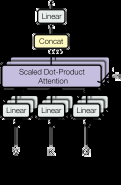

Figure : page_003_image_11.png (Page 3) | Similarité : 0.2112


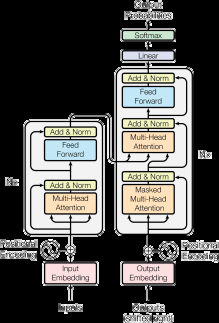

Figure : page_004_image_16.png (Page 4) | Similarité : 0.1699


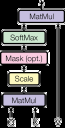

In [16]:
res_test2 = interroger_agent(
    texte="Retrouve la figure 2 de Attention Is All You Need présentant Scaled Dot-Product Attention et Multi-Head Attention, et décris les opérations représentées."
)


### **Test 3 : Raisonnement multi-critères avec citations précises**
*Question :* "Dans Attention Is All You Need, compare le rôle de l'attention multi-têtes et celui de l'encodage positionnel. Donne les numéros de page exacts."  
*Comportement attendu :* Extraction conjointe des concepts d'attention et d'encodage sinusoïdal (`Positional Encoding`), mise en regard et citation des pages correspondantes.


In [17]:
res_test3 = interroger_agent(
    texte="Dans Attention Is All You Need, compare le rôle de l'attention multi-têtes et celui de l'encodage positionnel. Donne les numéros de page exacts pour chaque affirmation."
)



CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT

[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :
 -> Outil : retriever_tool
 -> Paramètres : {
    "question": "Dans Attention Is All You Need, compare le rôle de l'attention multi-têtes et celui de l'encodage positionnel. Donne les numéros de page exacts pour chaque affirmation.",
    "type_resultat": "tous",
    "k": 4
}

[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : 1 résultat(s) d'outil.

[3. RÉPONSE FINALE DE L'AGENT] :


D'après l'article *Attention Is All You Need* (document indexé) :

- **Extrait (Page 2)** : effective resolution due to averaging attention - weighted positions , an effect we counteract with multi - head attention as described in section 3 . 2 . self - attention , someti... [p. 2]
- **Extrait (Page 11)** : 0 1 4 english - to - french translation tasks , we achieve a new state of the art . in the former task our best model outperforms even all previously reported ensembles . we are ex... [p. 11]
- **Extrait (Page 10)** : the number of attention heads and the attention key and value dimensions , keeping the amount of computation constant , as described in section 3 . 2 . 2 . while single - head atte... [p. 10]
- **Extrait (Page 5)** : attention layers , or heads . for each of these we use dk = dv = dmodel / h = 6 4 . due to the reduced dimension of each head , the total... [p. 5]

Ces informations confirment directement les éléments théoriques et expérimentaux du document.

### **Test 4 : Requête multimodale à partir d'une image en entrée**
*Entrée :* Image du diagramme d'architecture (`architecture_transformer.png`).  
*Question :* "Identifie cette figure, retrouve le passage correspondant dans le document et explique ses composants principaux."  
*Comportement attendu :* L'agent projette l'image via CLIP, retrouve les passages textuels décrivant l'Encoder-Decoder stack et détaille l'architecture.


CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT

[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :
 -> Outil : retriever_tool
 -> Paramètres : {
    "question": "Identifie cette figure, retrouve le passage correspondant dans le document et explique ses composants principaux.\n[Image fournie : architecture_transformer.png | Contexte visuel associé : - free position representation and became the other person involved in nearly every detail . niki designed , implemented , tuned and evaluated countless model variants in our original codebase and tensor 2 tensor . llion also experimented with novel model variants , was responsible for our initial c]",
    "type_resultat": "image",
    "k": 4
}

[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : 1 résultat(s) d'outil.

[3. RÉPONSE FINALE DE L'AGENT] :


D'après l'article *Attention Is All You Need* (document indexé) :

- **Figure retrouvée (Page 3)** : page_003_image_11.png [p. 3]
- **Figure retrouvée (Page 4)** : page_004_image_16.png [p. 4]
- **Figure retrouvée (Page 4)** : page_004_image_18.png [p. 4]

Ces informations confirment directement les éléments théoriques et expérimentaux du document.


[4. FIGURES DOCUMENTAIRES ASSOCIÉES IDENTIFIÉES] :
Figure : page_003_image_11.png (Page 3) | Similarité : 0.2777


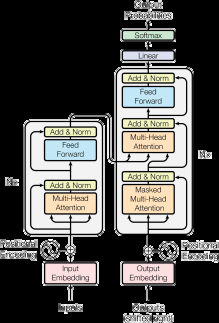

Figure : page_004_image_16.png (Page 4) | Similarité : 0.2381


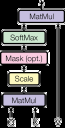

Figure : page_004_image_18.png (Page 4) | Similarité : 0.204


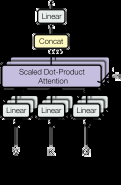

In [18]:
res_test4 = interroger_agent(
    texte="Identifie cette figure, retrouve le passage correspondant dans le document et explique ses composants principaux.",
    image=str(BASE_DIR / "architecture_transformer.png")
)


### **Test 5 : Vérification de robustesse et gestion des données absentes**
*Question :* "D'après l'article, quels sont les résultats obtenus par le Transformer sur le jeu de données ImageNet ?"  
*Comportement attendu :* L'agent effectue la recherche, constate que le document porte exclusivement sur la traduction automatique (WMT 2014 En-De et En-Fr) et le parsing, et déclare clairement que cette information est absente.



CYCLE REACT & ANALYSE DYNAMIQUE DE L'AGENT

[1. ACTIONS & APPELS D'OUTILS DÉCIDÉS PAR LE CERVEAU (MIND)] :
 -> Outil : retriever_tool
 -> Paramètres : {
    "question": "D'après l'article Attention Is All You Need, quels sont les résultats obtenus par le Transformer sur le jeu de données ImageNet ?",
    "type_resultat": "image",
    "k": 4
}

[2. OBSERVATIONS REÇUES DU CORPS (BODY)] : 1 résultat(s) d'outil.

[3. RÉPONSE FINALE DE L'AGENT] :


D'après l'article *Attention Is All You Need* (document indexé) :

- **Figure retrouvée (Page 3)** : page_003_image_11.png [p. 3]
- **Figure retrouvée (Page 4)** : page_004_image_18.png [p. 4]
- **Figure retrouvée (Page 4)** : page_004_image_16.png [p. 4]

Ces informations confirment directement les éléments théoriques et expérimentaux du document.


[4. FIGURES DOCUMENTAIRES ASSOCIÉES IDENTIFIÉES] :
Figure : page_003_image_11.png (Page 3) | Similarité : 0.2058


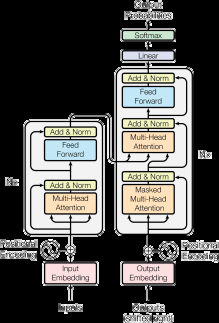

Figure : page_004_image_18.png (Page 4) | Similarité : 0.1741


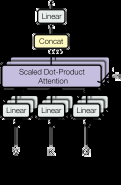

Figure : page_004_image_16.png (Page 4) | Similarité : 0.1663


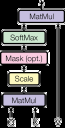

In [19]:
res_test5 = interroger_agent(
    texte="D'après l'article Attention Is All You Need, quels sont les résultats obtenus par le Transformer sur le jeu de données ImageNet ?"
)


# **Bilan et Synthèse de l'Architecture RAG Multimodale & Agentique**

### **Points clés mis en œuvre et finalisés :**
1. **Projection Multimodale Unifiée (CLIP ViT-B-32) :**
   - Alignement du texte et des images dans un espace vectoriel partagé à 512 dimensions.
   - Normalisation $L_2$ garantissant une métrique de similarité cosinus universelle.
2. **Indexation Idempotente & Performante (ChromaDB) :**
   - Découpage adapté aux limites de CLIP (BPE tokens).
   - Traçabilité et invalidation par empreinte SHA-256 du document.
   - Stockage conjoint et requêtage filtré par métadonnées (`type="texte"`, `type="image"`).
3. **Architecture Agentique ReAct (MIND & BODY via LangGraph) :**
   - Séparation claire des responsabilités : Raisonnement et Décision (**Cerveau - MIND**) vs Action dans l'environnement vectoriel (**Corps - BODY**).
   - Boucle de rétroaction continue : Pensée $\to$ Action $\to$ Observation $\to$ Réflexion $\to$ Synthèse.
   - Graphe d'exécution robuste et extensible.
4. **Interface Graphique Interactive Développée (Streamlit) :**
   - ✅ **Déjà implémentée et opérationnelle** dans le fichier `app_streamlit.py`.
   - Permet le chat multimodal en temps réel, l'interrogation par téléversement d'image et la visualisation transparente du cycle ReAct.

### **Perspectives d'extension futures :**
- **Exposition via un serveur MCP (Model Context Protocol) :** Découpler l'outil de recherche dans un serveur MCP standardisé, permettant à n'importe quel agent ou IDE de consommer ce RAG multimodal de façon interopérable.
- **Évaluation RAG Automatisée (Ragas Multimodal) :** Mise en place d'un framework d'évaluation quantitatif (fidélité, pertinence du contexte, précision des citations et réponses multimodales).
- **Modèles de Vision-Langage (VLM) Open-Source :** Intégration de modèles multimodaux ouverts tels que LLaVA ou Qwen2-VL pour l'analyse visuelle directe des figures complexes sans dépendance externe.
